<a href="https://colab.research.google.com/github/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/14_Lab_PrediccionesML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio 14 — Predicciones sobre grafos con ML tradicional
## Cristal y líquido en un coloide real: nodos, relaciones y grafos

**Computación Científica Avanzada · Unidad 4, sesión 2**

En una muestra coloidal coexisten un cristal y un líquido. Con solo las posiciones medidas de las partículas, convertidas en un **grafo de vecinos**, vamos a responder una pregunta de cada una de las tres tareas de Hamilton §1.2:

| Parte | Tarea | Pregunta |
|---|---|---|
| A | Clasificación de nodos | ¿Es cristalina esta partícula? |
| B | Predicción de relaciones | ¿Qué partículas serán vecinas dentro de 100 s? |
| C | Clasificación de grafos | ¿Qué capas de la muestra son cristal y dónde está la interfaz? |

En parejas se resuelven las preguntas, se entregan los laboratorios de manera individual por el git de la clase y en parejas se hace una exposición de las soluciones en clase. Las celdas con `# COMPLETAR` son las que deben escribir; hay una celda de verificación con `assert`. Al final del lab hay una celda para declarar las asistencia de la IA.

# Parte 0 — Preparación

### Coloides
Un coloide es una suspensión de partículas sólidas, de unos cientos de nanómetros a unos micrones, en un líquido. Las partículas se mueven por movimiento browniano y, si la repulsión entre ellas es de corto alcance, se comportan aproximadamente como esferas duras. Para esferas duras ideales, la única variable termodinámica es la fracción de volumen $\phi$, la fracción del espacio ocupada por partículas:

- para $\phi<0{,}494$ el sistema es líquido: partículas desordenadas que difunden;
- para $\phi>0{,}545$ es cristal: las partículas se ordenan en una red compacta y vibran alrededor de sus sitios;
- entre ambos valores, cristal y líquido coexisten, separados por una interfaz.

En esferas duras ideales la transición la produce solo la entropía: a alta densidad, ordenarse deja a cada partícula más espacio para moverse. Por la misma razón la interfaz cuesta energía libre: allí las partículas no se empaquetan bien ni como cristal ni como líquido, y eso da una tensión superficial de origen entrópico. Como las partículas son mil veces más grandes que un átomo y mucho más lentas, los coloides permiten estudiar experimentalmente estas fases partícula por partícula.

Las partículas de este experimento tienen una ligera carga eléctrica, que desplaza las fronteras de fase: los autores miden la congelación en $\phi_\text{freeze}=0{,}43$ y la fusión en $\phi_\text{melt}=0{,}49$. Su cristal está formado por capas hexagonales compactas apiladas al azar, una mezcla de los apilamientos fcc y hcp.

- $\phi_\text{freeze}$ («congelación») es la fracción de volumen a la que el **líquido** empieza a cristalizar cuando se va comprimiendo la muestra. Por debajo de $\phi_\text{freeze}$ todo es líquido.
- $\phi_\text{melt}$ («fusión») es la fracción de volumen a la que el **cristal** empieza a fundirse cuando se va diluyendo. Por encima de $\phi_\text{melt}$ todo es cristal.
- Entre las dos, el sistema se separa en dos fases que **coexisten**: un líquido con $\phi=\phi_\text{freeze}$ y un cristal con $\phi=\phi_\text{melt}$. Eso es lo que hay en la muestra del experimento, con la interfaz entre ambas.

### El experimento
Usamos los datos de Hernández-Guzmán y Weeks, PNAS 106, 15198 (2009), publicados en el [sitio del grupo de Eric Weeks](https://faculty.college.emory.edu/sites/weeks/data/jessy.html). Las partículas son de PMMA (polimetilmetacrilato), con diámetro $d=2{,}30\pm0{,}02$ µm y una polidispersidad de un 5 %, teñidas con un colorante fluorescente y suspendidas en una mezcla de bromuro de ciclohexilo y decalina. La mezcla iguala casi la densidad y el índice de refracción de las partículas, pero los autores añadieron a propósito un poco más de decalina, de modo que las partículas son ligeramente más densas que el líquido. La muestra, en una celda de $0{,}4\times3\times30$ mm³ guardada en vertical, se dejó equilibrar más de un mes. La gravedad produce así un gradiente de concentración: abajo, donde las partículas se acumulan, hay cristal; arriba, líquido; y en medio una interfaz en equilibrio, que ni crece ni se funde durante la medida.

Un microscopio confocal toma un volumen de $20\times55\times60$ µm³ cada 25 s durante 3750 s (algo más de una hora), con una resolución de 0,05–0,1 µm en la posición de cada partícula. Un programa de seguimiento localiza cada partícula y la identifica de un instante al siguiente.

Orientación de los ejes. En el archivo, el eje $x$ (unos 58 µm) es la dirección de la gravedad, que el artículo llama $z$: el cristal está a $x$ pequeño (abajo) y el líquido a $x$ grande (arriba). El eje $z$ del archivo (unos 20 µm) es el eje óptico del microscopio. La interfaz no es exactamente perpendicular a $x$: está inclinada unos 15°, y los autores rotan los datos para alinearla. Además se ondula por ondas capilares, que mueven su posición hasta unos 4 diámetros de pico a pico. Nosotros trabajaremos con capas perpendiculares a $x$ sin rotar, así que nuestros perfiles saldrán algo más anchos que los del artículo.

### El archivo
Cada fila es una partícula en un instante:

| columna | significado |
|---|---|
| `x, y, z` | posición en µm |
| `N_o` | número de vecinos **ordenados** (ver abajo). Los autores llaman cristalina a una partícula si $N_o\ge8$, es decir, $N_o>7$ |
| `c` | coordinación: número de vecinos a menos de $1{,}41\,d$, el primer mínimo de la función de distribución radial $g(r)$ del líquido |
| `t` | instante, de 0 a 149 (cada paso son 25 s) |
| `ID` | identificador de la partícula, el mismo en todos los instantes |

`N_o` resume el **orden orientacional**: en un cristal los enlaces con los vecinos apuntan en direcciones fijas, en un líquido no. Para medirlo, los autores calculan para cada partícula $i$ el **parámetro de orden de enlaces** de Steinhardt, un vector de $2l+1=13$ componentes complejas
$$
\hat q_{6m}(i)\propto\sum_{j\in\mathcal N(i)}Y_{6m}(\hat{\mathbf r}_{ij}),\qquad m=-6,\dots,6,
$$
normalizado a longitud 1, donde $\hat{\mathbf r}_{ij}$ es la dirección hacia el vecino $j$ y $Y_{6m}$ son armónicos esféricos. Dos vecinos son ordenados si $\sum_m\hat q_{6m}(i)\,\hat q_{6m}^*(j)>0{,}5$, es decir, si sus entornos apuntan en direcciones parecidas. $N_o$ será la etiqueta experimental de las partes A y C; los rasgos saldrán únicamente del grafo.

### El grafo
Unimos dos partículas si sus centros están a menos de $r_c=1{,}41\,d=3{,}24$ µm, el mismo criterio de vecinos del artículo y de la columna `c`. El grafo sabe cuántos vecinos tiene cada partícula y si esos vecinos se conocen entre sí, pero no en qué direcciones están. Tenga presente esa diferencia durante todo el ejercicio.

# Parte 1 — Datos y grafo

## 1.1 Librerías y descarga
El archivo pesa 6,3 MB comprimido. Si la descarga falla, bájelo a mano desde el sitio del grupo y súbalo a Colab con el icono de carpeta del panel izquierdo.

In [ ]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile
from scipy.spatial import cKDTree
from scipy.sparse import triu
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

In [ ]:
if not Path("hp02s5bb.txt").exists():
    if not Path("pnas09.zip").exists():
        urlretrieve("https://faculty.college.emory.edu/sites/weeks/data/pnas09.zip", "pnas09.zip")
    ZipFile("pnas09.zip").extractall()

datos = np.loadtxt("hp02s5bb.txt")
t = datos[:, 5].astype(int)
print(datos.shape[0], "filas,", np.unique(t).size, "instantes,", np.unique(datos[:, 6]).size, "partículas distintas")

726988 filas, 150 instantes, 27661 partículas distintas


In [ ]:
d = 2.30            # diámetro de las partículas, µm
rc = 1.41 * d       # radio de vecinos, µm

def instante(k):
    """Posiciones (n x 3), N_o, coordinación c e ID de las partículas del instante k."""
    f = datos[t == k]
    return f[:, :3], f[:, 3], f[:, 4], f[:, 6].astype(int)

X, N_o, c, ID = instante(0)
cristalina = N_o > 7
print(len(X), "partículas en t = 0; caja (µm):", np.round(X.min(axis=0), 1), "a", np.round(X.max(axis=0), 1))

4691 partículas en t = 0; caja (µm): [0.2 0.1 0.2] a [58.5 54.3 20.1]


Una lámina delgada de la muestra ($z$ entre 8 y 10 µm), con las partículas cristalinas según los autores en azul. El cristal está a la izquierda, que en el experimento es abajo.

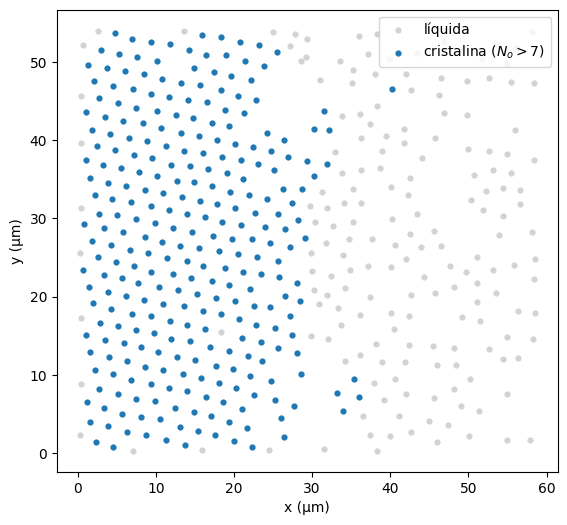

In [ ]:
lamina = (X[:, 2] > 8) & (X[:, 2] < 10)
plt.figure(figsize=(7, 6))
plt.scatter(*X[lamina & ~cristalina, :2].T, s=12, color="lightgray", label="líquida")
plt.scatter(*X[lamina & cristalina, :2].T, s=12, color="tab:blue", label="cristalina ($N_o>7$)")
plt.xlabel("x (µm)"); plt.ylabel("y (µm)"); plt.gca().set_aspect("equal"); plt.legend(loc="upper right")
plt.show()

## Tarea 1. Grafo de vecinos
Complete `grafo_de_vecinos`. Con unas 4800 partículas conviene un **árbol k-d** (`scipy.spatial.cKDTree`): su método `query_pairs(r)` devuelve los pares $(i, j)$, con $i<j$, a distancia menor que `r`, sin calcular todas las distancias.

*Sugerencia para el asistente de IA:* «¿Cómo construyo con `scipy.spatial.cKDTree` y NetworkX un grafo cuyos nodos sean las filas 0..n-1 de un arreglo X y cuyas aristas unan los pares a menos de r?». Asegúrese de que el grafo incluya también las partículas sin vecinos.

In [ ]:
def grafo_de_vecinos(X, rc):
    """Grafo con un nodo por fila de X (nodos 0, ..., n-1) y una arista entre
    las partículas cuyos centros están a menos de rc."""
    # COMPLETAR
    X = np.asarray(X)
    n = len(X)
    tree = cKDTree(X)
    # Pares (i, j) con i < j y distancia <= r, como arreglo (m, 2)
    pares = tree.query_pairs(rc, output_type="ndarray")

    G = nx.Graph()
    G.add_nodes_from(range(n))   # incluye nodos sin vecinos
    G.add_edges_from(pares)      # cada fila es una arista
    return G
    #raise NotImplementedError("Complete esta función")

In [ ]:
# Verificación de la tarea 1
G = grafo_de_vecinos(X, rc)
grado = np.array([G.degree(u) for u in range(len(X))])
assert G.number_of_nodes() == len(X)
coincide = np.mean(grado == c)
assert coincide > 0.95, f"El grado debería coincidir con la columna c en casi todas las partículas ({coincide:.2f})"
print(f"Tarea 1 correcta: {G.number_of_edges()} aristas; el grado coincide con la coordinación de los autores en el {100 * coincide:.0f} % de las partículas")

Tarea 1 correcta: 22963 aristas; el grado coincide con la coordinación de los autores en el 98 % de las partículas


### Ver el grafo
Un grafo de 4800 nodos en 3D es ilegible. La función `dibujar` muestra solo una **ventana**: las partículas dentro de una caja, con las aristas entre ellas, proyectadas sobre dos ejes. La usaremos en todo el cuaderno.

In [ ]:
def ventana(X, x=(0, 60), y=(0, 60), z=(0, 25)):
    """Índices de las partículas dentro de la caja dada (en µm)."""
    m = ((X[:, 0] >= x[0]) & (X[:, 0] < x[1]) & (X[:, 1] >= y[0]) & (X[:, 1] < y[1])
         & (X[:, 2] >= z[0]) & (X[:, 2] < z[1]))
    return np.where(m)[0]

def dibujar(G, X, nodos, colores="tab:blue", ejes=(0, 1), ax=None, **opciones):
    """Dibuja el subgrafo de los nodos dados, proyectado sobre los ejes elegidos (0 = x, 1 = y, 2 = z)."""
    ax = ax or plt.gca()
    pos = {u: X[u, list(ejes)] for u in nodos}
    nx.draw_networkx_edges(G.subgraph(nodos), pos, ax=ax, edge_color="0.75", width=0.8)
    nx.draw_networkx_nodes(G.subgraph(nodos), pos, nodelist=list(nodos), node_color=colores,
                           node_size=opciones.pop("node_size", 40), ax=ax, **opciones)
    ax.set_xlabel("xyz"[ejes[0]] + " (µm)"); ax.set_ylabel("xyz"[ejes[1]] + " (µm)")
    ax.set_aspect("equal"); ax.tick_params(left=True, bottom=True, labelleft=True, labelbottom=True)

Una ventana que cruza la interfaz, coloreada por el grado. A la izquierda se ve la red del cristal, con nodos de grado alto; a la derecha, el líquido, más ralo e irregular.

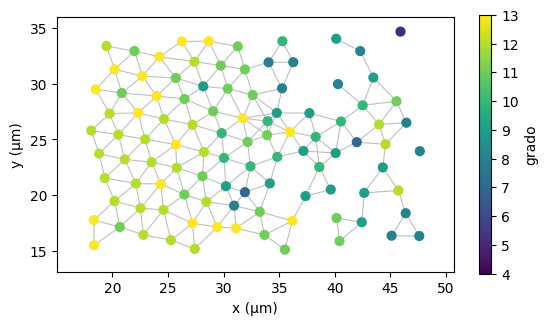

In [ ]:
zona_interfaz = ventana(X, x=(18, 48), y=(15, 35), z=(8, 10.5))
dibujar(G, X, zona_interfaz, colores=grado[zona_interfaz], cmap="viridis", vmin=4, vmax=13)
plt.colorbar(plt.gca().collections[-1], label="grado", shrink=0.7)
plt.show()

**Discutan (1 min): ¿Por qué casi todos los nodos tienen menos aristas dibujadas que su grado? ¿Dónde están los vecinos que faltan? Cuidado: aquí la dirección perpendicular al dibujo es $z$, el eje óptico del microscopio, no la dirección de la gravedad, que es $x$.

# Parte A — Clasificación de nodos: ¿es cristalina esta partícula?

Los autores clasificaron cada partícula con el orden orientacional ($N_o\ge8$). Suponga que solo conoce esa etiqueta para el **30 % de las partículas**, elegidas al azar, y quiere predecir la del resto a partir del grafo. Note que los nodos no son independientes: una partícula cristalina suele tener vecinos cristalinos, y la agregación de vecindario aprovecha esa correlación.

## Tarea 2. Rasgos de nodo
Complete `rasgos_de_nodo`. Debe devolver una matriz $F$ de forma $(n, 5)$ con estas columnas, en este orden:

| columna | rasgo | definición |
|---|---|---|
| 0 | grado | $d_u=\sum_vA[u,v]$ |
| 1 | agrupamiento | fracción de pares de vecinos de $u$ conectados |
| 2 | agregación de grado, ronda 1 | $\mathbf h^{(1)}=A\,\mathbf d$ |
| 3 | agregación de grado, ronda 2 | $\mathbf h^{(2)}=A\,\mathbf h^{(1)}$ |
| 4 | agrupamiento medio de los vecinos | $(A\,\mathbf c)_u/d_u$ (0 si $d_u=0$) |

Use una matriz de adyacencia **dispersa**, `nx.to_scipy_sparse_array(G, nodelist=range(n), format="csr")`: la densa tendría 23 millones de entradas.



In [ ]:
nombres_nodo = ["grado", "agrupamiento", "h1", "h2", "agrupamiento vecinos"]

def rasgos_de_nodo(G):
    """Matriz (n, 5): grado, agrupamiento, h1 = A d, h2 = A h1 y agrupamiento medio
    de los vecinos, con las filas en el orden de los nodos 0, ..., n-1."""

    n = G.number_of_nodes()

    A = nx.to_scipy_sparse_array(
        G, nodelist=range(n), format="csr"
    )

    grado = np.asarray(A.sum(axis=1)).ravel()

    agrupamiento = np.array([
        nx.clustering(G, u) for u in range(n)
    ])

    h1 = A @ grado
    h2 = A @ h1

    agrupamiento_vecinos = np.divide(
        A @ agrupamiento,
        grado,
        out=np.zeros(n),
        where=grado != 0
    )

    F = np.column_stack([
        grado,
        agrupamiento,
        h1,
        h2,
        agrupamiento_vecinos
    ])

    return F

In [ ]:
# Verificación de la tarea 2
F = rasgos_de_nodo(G)
u = 100
assert F.shape == (len(X), 5)
assert np.allclose(F[:, 0], grado), "Revise el grado"
assert np.isclose(F[u, 1], nx.clustering(G, u)), "Revise el agrupamiento"
assert np.isclose(F[u, 2], sum(G.degree(v) for v in G[u])), "h1(u) es la suma de los grados de los vecinos"
assert np.isclose(F[u, 4], np.mean([nx.clustering(G, v) for v in G[u]])), "Revise el agrupamiento de los vecinos"
print("Tarea 2 correcta")

Tarea 2 correcta


## Tarea 3. Entrenar
Complete `entrenar`: debe devolver `make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))` ajustado a los datos. La misma función servirá en la parte C.



In [ ]:
def entrenar(F_train, y_train):
    """Regresión logística, con los rasgos estandarizados, ajustada a (F_train, y_train)."""

    modelo = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    )

    modelo.fit(F_train, y_train)

    return modelo

La celda siguiente separa 30 % de partículas etiquetadas y 70 % por predecir, entrena con distintas combinaciones de rasgos y reporta la exactitud en toda la muestra y en la franja de la interfaz ($27<x<36$ µm). Repite con 10 semillas.

In [ ]:
y_nodo = cristalina.astype(int)
franja = (X[:, 0] > 27) & (X[:, 0] < 36)
combinaciones = {"solo grado": [0], "grado + agrupamiento": [0, 1], "todos (con agregación)": [0, 1, 2, 3, 4]}

base = max(y_nodo.mean(), 1 - y_nodo.mean())
base_franja = max(y_nodo[franja].mean(), 1 - y_nodo[franja].mean())
print(f"{'rasgos':<26} {'toda la muestra':>16} {'interfaz':>10}")
print(f"{'línea base':<26} {base:>16.3f} {base_franja:>10.3f}")
for nombre, cols in combinaciones.items():
    total, interfaz = [], []
    for semilla in range(10):
        tr, te = train_test_split(np.arange(len(X)), train_size=0.3, random_state=semilla, stratify=y_nodo)
        modelo = entrenar(F[tr][:, cols], y_nodo[tr])
        total.append(modelo.score(F[te][:, cols], y_nodo[te]))
        te_f = te[franja[te]]
        interfaz.append(modelo.score(F[te_f][:, cols], y_nodo[te_f]))
    print(f"{nombre:<26} {np.mean(total):>16.3f} {np.mean(interfaz):>10.3f}")

rasgos                      toda la muestra   interfaz
línea base                            0.562      0.531
solo grado                            0.772      0.577
grado + agrupamiento                  0.811      0.608
todos (con agregación)                0.891      0.684


### Ver los aciertos y los errores
Con el modelo de todos los rasgos (la última semilla), coloreamos la ventana de la interfaz por la etiqueta de los autores y marcamos con borde rojo las partículas mal clasificadas.

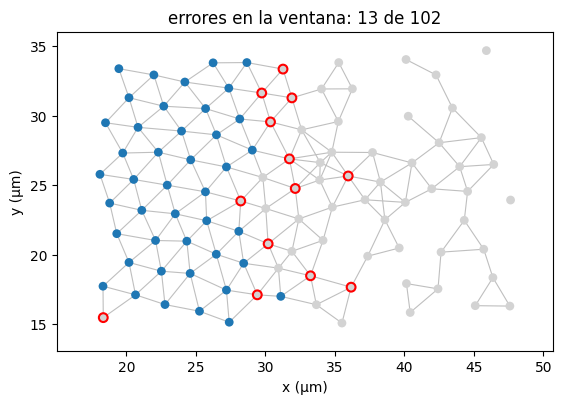

In [ ]:
prediccion = modelo.predict(F)
nodos = zona_interfaz
error = prediccion[nodos] != y_nodo[nodos]
dibujar(G, X, nodos, colores=np.where(y_nodo[nodos] == 1, "tab:blue", "lightgray"),
        edgecolors=np.where(error, "red", "none"), linewidths=1.5)
plt.title(f"errores en la ventana: {error.sum()} de {len(nodos)}")
plt.show()

**Discutan:** ¿dónde se concentran los errores? ¿Por qué la agregación mejora la exactitud? Piense en el campo receptivo: con $h^{(2)}$, cada partícula "ve" a sus vecinos a dos saltos. ¿Por qué la exactitud cae tanto en la interfaz?

# Parte B — Predicción de relaciones: ¿quiénes serán vecinos?

En un líquido las partículas cambian de vecinos (la "jaula" que forman sus vecinos se reorganiza), y en un cristal casi no. Los autores midieron esta diferencia con el desplazamiento de las partículas: la movilidad sube del cristal al líquido a lo largo de unos $2{,}4\,d$, y en el líquido la difusión es unas 50 veces más lenta que en una suspensión diluida, porque la muestra es muy densa. Con el grafo en el instante $t$, ¿podemos predecir qué parejas de partículas serán vecinas en $t+\Delta t$, con $\Delta t=100$ s (4 instantes)?

**Candidatos.** Dos partículas a dos saltos en el grafo, es decir, no vecinas pero con al menos un vecino común, son las candidatas naturales a volverse vecinas. Para cada candidata usaremos como puntaje el número de vecinos comunes, que es $A^2[u,v]$ (sesión 1).

**Etiqueta.** La pareja es positiva si en $t+\Delta t$ sus centros están a menos de $r_c$. Como las partículas se identifican por su `ID`, la celda siguiente (ya escrita) construye las aristas del instante futuro expresadas con los índices del instante 0.

In [ ]:
dt = 4                                              # instantes; 4 x 25 s = 100 s
X_f, _, _, ID_f = instante(dt)
indice = {i: j for j, i in enumerate(ID)}          # ID -> índice del nodo en el instante 0
ids_f = set(ID_f)
presentes = np.array([i in ids_f for i in ID])      # partículas que siguen en la imagen en t + dt
futuras = set()
for a, b in cKDTree(X_f).query_pairs(rc):
    if ID_f[a] in indice and ID_f[b] in indice:
        u, v = sorted((indice[ID_f[a]], indice[ID_f[b]]))
        futuras.add((u, v))
print(len(futuras), "aristas en t + dt entre partículas presentes en t = 0")

18476 aristas en t + dt entre partículas presentes en t = 0


## Tarea 4. Parejas a dos saltos y sus vecinos comunes
Complete `pares_a_dos_saltos`. Debe devolver un arreglo `P` de forma $(m, 2)$ con todas las parejas $u<v$ **no vecinas** que tienen al menos un vecino común, y un arreglo `vc` con el número de vecinos comunes de cada pareja. Una forma eficiente: las entradas no nulas de $A^2$ fuera de la diagonal son exactamente las parejas con vecinos comunes, y su valor es cuántos; quedan por quitar las parejas que ya son vecinas.



In [ ]:

def pares_a_dos_saltos(G):
    """Parejas u < v no vecinas con al menos un vecino común (arreglo m x 2)
    y el número de vecinos comunes de cada una (arreglo de longitud m)."""

    n = G.number_of_nodes()

    A = nx.to_scipy_sparse_array(
        G, nodelist=range(n), format="csr", dtype=np.int64
    )

    A2 = A @ A

    filas, columnas = A2.nonzero()

    pares = []
    puntajes = []

    for u, v in zip(filas, columnas):
        if u < v and not G.has_edge(u, v):
            pares.append((u, v))
            puntajes.append(int(A2[u, v]))

    pares = np.asarray(pares, dtype=int).reshape(-1, 2)
    puntajes = np.asarray(puntajes, dtype=int)

    return pares, puntajes


In [ ]:
# Verificación de la tarea 4
P, vc = pares_a_dos_saltos(G)
assert P.shape[1] == 2 and len(P) == len(vc) and np.all(P[:, 0] < P[:, 1])
assert not any(G.has_edge(u, v) for u, v in P[:2000]), "Las parejas no pueden ser ya vecinas"
for k in [0, 500, 5000]:
    u, v = P[k]
    assert vc[k] == len(set(G[u]) & set(G[v])), "Revise el conteo de vecinos comunes"
print(f"Tarea 4 correcta: {len(P)} parejas a dos saltos")

Tarea 4 correcta: 74637 parejas a dos saltos


### ¿Predicen los vecinos comunes los vecinos futuros?
Nos quedamos con las parejas cuyas dos partículas siguen en la imagen, calculamos la etiqueta y medimos el AUC del puntaje de vecinos comunes. Como comparación usamos la **distancia** actual entre las dos partículas (menor distancia, mayor puntaje), que es información geométrica y no del grafo.

In [ ]:
validas = presentes[P[:, 0]] & presentes[P[:, 1]]
P_v, vc_v = P[validas], vc[validas]
y_rel = np.array([(u, v) in futuras for u, v in P_v]).astype(int)
distancia = np.linalg.norm(X[P_v[:, 0]] - X[P_v[:, 1]], axis=1)

zona = np.where(X[P_v[:, 0], 0] < 25, "cristal", np.where(X[P_v[:, 0], 0] > 40, "líquido", "interfaz"))
print(f"{'zona':<10} {'parejas':>8} {'positivos':>10} {'AUC vecinos comunes':>20} {'AUC distancia':>14}")
for z in ["cristal", "interfaz", "líquido", "todas"]:
    m = np.ones(len(y_rel), bool) if z == "todas" else zona == z
    print(f"{z:<10} {m.sum():>8} {y_rel[m].mean():>10.3f} {roc_auc_score(y_rel[m], vc_v[m]):>20.3f}"
          f" {roc_auc_score(y_rel[m], -distancia[m]):>14.3f}")

zona        parejas  positivos  AUC vecinos comunes  AUC distancia
cristal       39036      0.008                0.898          0.963
interfaz      18069      0.040                0.752          0.873
líquido        3225      0.105                0.643          0.784
todas         60330      0.023                0.719          0.847


### Ver una jaula que se reorganiza
Elegimos una partícula del líquido y dibujamos su vecindario a dos saltos en $t=0$ (aristas grises). Encima marcamos en verde las aristas que aparecen en $t+\Delta t$ y en rojo las que desaparecen. La proyección es sobre $(x, y)$, así que dos partículas pueden parecer cercanas aunque estén separadas en $z$.

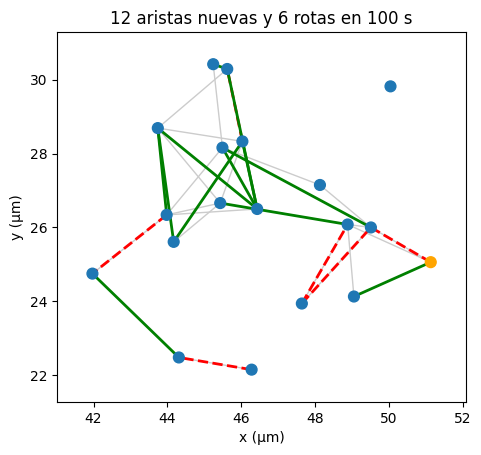

In [ ]:
centro = ventana(X, x=(44, 48), y=(25, 29), z=(8, 12))[0]
vecindario = list(nx.single_source_shortest_path_length(G, centro, cutoff=2))
vecindario = [u for u in vecindario if presentes[u]]
H = G.subgraph(vecindario)
nuevas = [(u, v) for u in vecindario for v in vecindario if u < v and (u, v) in futuras and not G.has_edge(u, v)]
rotas = [(u, v) for u, v in H.edges() if tuple(sorted((u, v))) not in futuras]

pos = {u: X[u, :2] for u in vecindario}
nx.draw_networkx_edges(H, pos, edge_color="0.8")
nx.draw_networkx_edges(H, pos, edgelist=rotas, edge_color="red", width=2, style="dashed")
nx.draw_networkx_edges(nx.Graph(nuevas), pos, edge_color="green", width=2)
nx.draw_networkx_nodes(H, pos, node_size=60, node_color=["orange" if u == centro else "tab:blue" for u in vecindario])
plt.title(f"{len(nuevas)} aristas nuevas y {len(rotas)} rotas en {25 * dt} s")
plt.gca().set_aspect("equal"); plt.xlabel("x (µm)"); plt.ylabel("y (µm)")
plt.gca().tick_params(left=True, bottom=True, labelleft=True, labelbottom=True)
plt.show()

**Discutan:** ¿en qué zona se forman más enlaces nuevos y por qué? ¿Por qué el AUC no se ve afectado por que los positivos sean tan pocos? La distancia predice mejor que los vecinos comunes: ¿qué dice eso sobre la información que el grafo descarta?


# Parte B. Predicción de enlaces en partículas coloidales

## 1. ¿En qué zona cambian más los vecinos y por qué?

La región líquida presenta la mayor proporción de conexiones nuevas entre las parejas candidatas estudiadas.

| Región | Conexiones nuevas |
|---|---:|
| Cristal | 0.8 % |
| Interfaz | 4.0 % |
| Líquido | 10.5 % |

**Explicación física:**

En el cristal, las partículas mantienen posiciones relativamente estables debido a su organización estructural. Por eso, las relaciones de vecindad cambian menos.

En el líquido, las partículas tienen mayor movilidad y reorganizan sus vecinos con más facilidad.

**Conclusión:** la región líquida presenta mayor formación relativa de conexiones nuevas. Estos porcentajes no incluyen las conexiones que se rompen.

---

## 2. ¿Por qué la distancia predice mejor que los vecinos comunes?

Porque la distancia conserva información geométrica que el grafo binario descarta.

La conexión entre dos partículas se define mediante:

$$
A_{uv}=
\begin{cases}
1, & r_{uv}\leq r_c,\\
0, & r_{uv}>r_c.
\end{cases}
$$

Donde:

$$
r_c=3.243\,\mu m
$$

El grafo indica si dos partículas están conectadas, pero no conserva su separación exacta.

Por ejemplo, dos parejas separadas por 3.3 y 5.0 micrómetros aparecen desconectadas, aunque la primera está mucho más cerca del umbral de conexión.

### Resultados

| Predictor | AUC global |
|---|---:|
| Vecinos comunes | 0.719 |
| Distancia inicial | 0.847 |

**Conclusión:** la distancia inicial tiene mayor capacidad predictiva porque conserva información espacial continua.

---

## 3. ¿Qué es el AUC?

El AUC (*Area Under the ROC Curve*) mide la capacidad de un puntaje para distinguir entre casos positivos y negativos.

En nuestro experimento:

- **Positivo (1):** la pareja formó una conexión.
- **Negativo (0):** la pareja no formó una conexión.

Una expresión matemática del AUC es:

$$
\boxed{
AUC=
\frac{
N_{\mathrm{correctas}}+
\frac{1}{2}N_{\mathrm{empates}}
}{
N_+N_-
}
}
$$

Donde:

- $N_+$: número de positivos.
- $N_-$: número de negativos.
- $N_{\mathrm{correctas}}$: comparaciones donde el positivo recibe mayor puntaje.
- $N_{\mathrm{empates}}$: comparaciones con puntajes iguales.

### Interpretación

- **AUC = 1:** discriminación perfecta.
- **AUC = 0.5:** capacidad discriminativa equivalente al azar.
- **AUC cercano a 1:** buena capacidad para ordenar positivos por encima de negativos.

**Importante:** un AUC alto no significa que se formen más conexiones ni que todas las predicciones individuales sean correctas.

---

## 4. ¿Por qué el AUC puede ser alto aunque existan pocos positivos?

Porque el AUC mide la capacidad de distinguir positivos de negativos, no la cantidad de conexiones formadas.

En el cristal obtuvimos:

$$
\text{Fracción de conexiones nuevas}=0.008
$$

$$
AUC_{\mathrm{distancia}}=0.963
$$

Esto significa que, aunque solamente el 0.8 % de las parejas candidatas se conectaron, la distancia inicial permite distinguir muy bien las parejas positivas de las negativas.

**Conclusión:** la proporción de positivos no determina directamente el AUC. Sin embargo, pocos positivos pueden aumentar la incertidumbre estadística de su estimación.

---

## 5. ¿Por qué el AUC disminuye en el líquido?

Los resultados del predictor basado en distancia fueron:

| Región | AUC distancia |
|---|---:|
| Cristal | 0.963 |
| Interfaz | 0.873 |
| Líquido | 0.784 |

En el cristal, la estructura es más estable y la distancia inicial permite anticipar mejor las conexiones futuras.

En el líquido, las partículas experimentan una reorganización más compleja, por lo que la distancia y los vecinos comunes tienen menor capacidad discriminativa.

Podría ser útil incorporar información adicional:

- Velocidades de las partículas.
- Desplazamientos anteriores.
- Movilidad local.
- Evolución temporal de los vecinos.

**Conclusión:** un AUC menor indica que el puntaje utilizado distingue peor los resultados, posiblemente porque no incorpora toda la información dinámica relevante.

---

## 6. ¿Qué observamos en la reorganización local de vecinos?

En la visualización de un vecindario durante 100 segundos encontramos:

- **12 conexiones nuevas**, representadas en verde.
- **6 conexiones rotas**, representadas en rojo.

Esto evidencia que las relaciones de vecindad cambian con el tiempo.

Las conexiones corresponden al vecindario seleccionado y no necesariamente involucran directamente a la partícula central.

---

## 7. Conclusión general de la Parte B

La región líquida presenta una mayor proporción de conexiones nuevas debido a la reorganización de sus partículas.

Sin embargo, la capacidad de predecir qué parejas se conectarán es mayor en el cristal.

La distancia inicial presenta un AUC superior al número de vecinos comunes en todas las regiones.

**Conclusión física principal:**

La topología del grafo contiene información útil sobre la evolución de las partículas, pero la representación binaria pierde información geométrica que resulta importante para predecir las conexiones futuras.


## Tarea 5 (opcional). Enlaces que se rompen
La pregunta inversa: de las aristas en $t=0$ entre partículas presentes en $t+\Delta t$, ¿cuáles se romperán? Calcule la fracción de aristas rotas en el cristal y en el líquido, y el AUC de dos puntajes: menos vecinos comunes (un enlace con muchos vecinos comunes está "protegido" por su entorno) y la longitud del enlace.

In [ ]:
# COMPLETAR (opcional): aristas de G entre partículas presentes, etiqueta "se rompe" y los dos AUC

# Tarea 5: enlaces que se rompen

# Matriz de adyacencia y vecinos comunes
A = nx.to_scipy_sparse_array(
    G, nodelist=range(len(X)), format="csr", dtype=np.int64
)
A2 = A @ A

# Aristas iniciales entre partículas presentes en ambos instantes
aristas = np.array([
    (min(u, v), max(u, v))
    for u, v in G.edges()
    if presentes[u] and presentes[v]
], dtype=int).reshape(-1, 2)

# Etiqueta: 1 si el enlace desaparece en t + dt
y_rotas = np.array([
    (u, v) not in futuras for u, v in aristas
], dtype=int)

# Puntaje 1: menos vecinos comunes = mayor riesgo de ruptura
vc_aristas = np.array([
    int(A2[u, v]) for u, v in aristas
])
puntaje_vecinos = -vc_aristas

# Puntaje 2: mayor distancia inicial = mayor riesgo de ruptura
longitud = np.linalg.norm(
    X[aristas[:, 0]] - X[aristas[:, 1]],
    axis=1
)

# Regiones espaciales
zona_aristas = np.where(
    X[aristas[:, 0], 0] < 25,
    "cristal",
    np.where(
        X[aristas[:, 0], 0] > 40,
        "líquido",
        "interfaz"
    )
)

print(f"{'zona':<10} {'aristas':>9} {'fracción rotas':>16} "
      f"{'AUC -vecinos':>15} {'AUC longitud':>15}")

for z in ["cristal", "interfaz", "líquido", "todas"]:
    m = (np.ones(len(y_rotas), dtype=bool)
         if z == "todas" else zona_aristas == z)

    fraccion = y_rotas[m].mean()

    if len(np.unique(y_rotas[m])) == 2:
        auc_vecinos = roc_auc_score(
            y_rotas[m], puntaje_vecinos[m]
        )
        auc_longitud = roc_auc_score(
            y_rotas[m], longitud[m]
        )
    else:
        auc_vecinos = np.nan
        auc_longitud = np.nan

    print(f"{z:<10} {m.sum():>9} {fraccion:>16.3f} "
          f"{auc_vecinos:>15.3f} {auc_longitud:>15.3f}")


zona         aristas   fracción rotas    AUC -vecinos    AUC longitud
cristal        12105            0.021           0.525           0.916
interfaz        5330            0.136           0.579           0.712
líquido          976            0.407           0.523           0.591
todas          18411            0.075           0.661           0.771


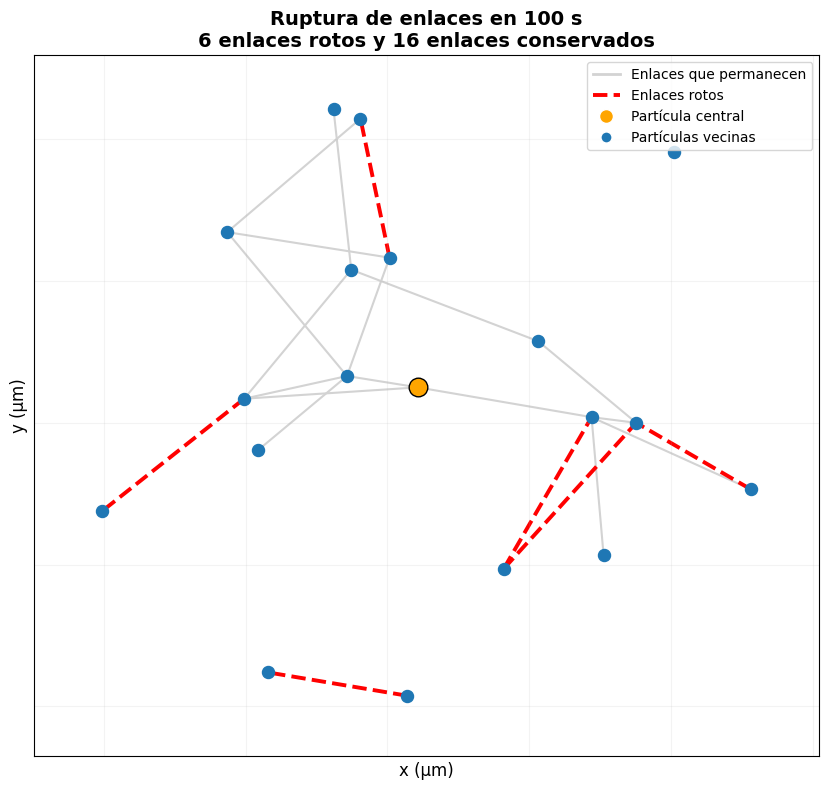

Enlaces iniciales: 22
Enlaces rotos: 6
Enlaces conservados: 16
Porcentaje de ruptura local: 27.27%


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

# =====================================================
# TAREA 5: VISUALIZACIÓN DE ENLACES QUE SE ROMPEN
# =====================================================

# 1. Seleccionar una partícula central en el líquido
centro = ventana(
    X,
    x=(44, 48),
    y=(25, 29),
    z=(8, 12)
)[0]

# 2. Obtener partículas hasta dos saltos del centro
vecindario = list(
    nx.single_source_shortest_path_length(
        G, centro, cutoff=2
    )
)

# Conservar partículas observadas en ambos tiempos
vecindario = [u for u in vecindario if presentes[u]]

# 3. Construir el subgrafo inicial
H = G.subgraph(vecindario).copy()

# 4. Identificar enlaces que se rompieron
rotas = [
    (u, v)
    for u, v in H.edges()
    if tuple(sorted((u, v))) not in futuras
]

# 5. Identificar enlaces que permanecieron
permanecen = [
    (u, v)
    for u, v in H.edges()
    if tuple(sorted((u, v))) in futuras
]

# 6. Posiciones iniciales proyectadas en XY
pos = {
    u: X[u, :2]
    for u in vecindario
}

# 7. Crear figura
fig, ax = plt.subplots(figsize=(10, 8))

# Enlaces que permanecen: gris
nx.draw_networkx_edges(
    H, pos,
    edgelist=permanecen,
    edge_color="lightgray",
    width=1.5,
    ax=ax
)

# Enlaces rotos: rojo discontinuo
nx.draw_networkx_edges(
    H, pos,
    edgelist=rotas,
    edge_color="red",
    width=2.8,
    style="dashed",
    ax=ax
)

# Partículas del vecindario: azul
nx.draw_networkx_nodes(
    H, pos,
    nodelist=[u for u in vecindario if u != centro],
    node_color="tab:blue",
    node_size=75,
    ax=ax
)

# Partícula central: naranja
nx.draw_networkx_nodes(
    H, pos,
    nodelist=[centro],
    node_color="orange",
    node_size=180,
    edgecolors="black",
    linewidths=1,
    ax=ax
)

# 8. Leyenda
from matplotlib.lines import Line2D

leyenda = [
    Line2D([0], [0], color="lightgray",
           lw=2, label="Enlaces que permanecen"),
    Line2D([0], [0], color="red",
           lw=2.8, linestyle="--",
           label="Enlaces rotos"),
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor="orange",
           markersize=10, label="Partícula central"),
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor="tab:blue",
           markersize=8, label="Partículas vecinas")
]

ax.legend(handles=leyenda, loc="best", fontsize=10)

# 9. Título y presentación
ax.set_title(
    f"Ruptura de enlaces en {25 * dt} s\n"
    f"{len(rotas)} enlaces rotos y "
    f"{len(permanecen)} enlaces conservados",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("x (µm)", fontsize=12)
ax.set_ylabel("y (µm)", fontsize=12)

ax.set_aspect("equal")
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()

# 10. Resumen numérico del vecindario
print(f"Enlaces iniciales: {H.number_of_edges()}")
print(f"Enlaces rotos: {len(rotas)}")
print(f"Enlaces conservados: {len(permanecen)}")

if H.number_of_edges() > 0:
    porcentaje = 100 * len(rotas) / H.number_of_edges()
    print(f"Porcentaje de ruptura local: {porcentaje:.2f}%")



# Parte B — Tarea 5. Predicción de enlaces que se rompen

## 1. Objetivo

El objetivo es identificar cuáles de las conexiones existentes en el instante inicial $t=0$ desaparecen después de un intervalo de 100 segundos.

Una conexión se considera rota cuando dos partículas que inicialmente eran vecinas dejan de cumplir la condición de vecindad:

$$
r_{uv}(t+\Delta t)>r_c
$$

donde:

$$
r_c=3.243\,\mu m,\qquad \Delta t=100\,s
$$

Las aristas representan relaciones de proximidad espacial, no enlaces químicos.

Solo se analizan parejas cuyas dos partículas están presentes en ambos instantes.

---

## 2. Resultados obtenidos

| Zona | Aristas iniciales | Fracción rotas | AUC -vecinos | AUC longitud |
|---|---:|---:|---:|---:|
| Cristal | 12105 | 0.021 | 0.525 | 0.916 |
| Interfaz | 5330 | 0.136 | 0.579 | 0.712 |
| Líquido | 976 | 0.407 | 0.523 | 0.591 |
| Todas | 18411 | 0.075 | 0.661 | 0.771 |

La fracción de enlaces rotos corresponde a:

$$
f_{\mathrm{rotas}}=
\frac{N_{\mathrm{aristas\ rotas}}}
{N_{\mathrm{aristas\ iniciales}}}
$$

En porcentajes:

- **Cristal:** 2.1 %.
- **Interfaz:** 13.6 %.
- **Líquido:** 40.7 %.


---

## 3. ¿En qué región se rompen más enlaces?

La mayor proporción de enlaces rotos aparece en la región líquida, donde desaparece el 40.7 % de las conexiones iniciales analizadas.

En comparación:

- En el cristal solamente desaparece el 2.1 %.
- En la interfaz desaparece el 13.6 %.
- En el líquido desaparece el 40.7 %.

Esto es coherente con las diferencias de movilidad entre las regiones.

En el cristal, las partículas conservan una estructura relativamente estable y mantienen gran parte de sus vecinos.

En el líquido, las partículas se desplazan y reorganizan continuamente sus entornos locales, lo que favorece la pérdida de conexiones iniciales.

**Conclusión física:** la región líquida presenta una reorganización de vecindad considerablemente mayor que la región cristalina.

Estos porcentajes expresan proporciones de ruptura, no cantidades absolutas.

---

## 4. ¿Qué puntajes utilizamos para predecir las rupturas?

Se utilizaron dos criterios.

### A. Número negativo de vecinos comunes

$$
s_1(u,v)=-(A^2)_{uv}
$$

La hipótesis es que una conexión con muchos vecinos comunes está más integrada en su entorno y podría ser más estable.

Por tanto, una conexión con pocos vecinos comunes recibe un puntaje de ruptura mayor.

### B. Longitud inicial del enlace

$$
s_2(u,v)=r_{uv}(0)
$$

La hipótesis es que una conexión inicialmente larga, cercana al radio máximo de vecindad, tiene mayor tendencia a desaparecer.

Esto ocurre porque un desplazamiento relativamente pequeño puede aumentar su separación por encima del umbral $r_c$.

Ambos puntajes se calculan con información inicial, antes de observar qué conexiones se rompen.

---

## 5. ¿Cuál de los dos puntajes predice mejor las rupturas?

Los resultados muestran que la longitud inicial supera al número negativo de vecinos comunes en las tres regiones.

| Región | AUC -vecinos | AUC longitud |
|---|---:|---:|
| Cristal | 0.525 | 0.916 |
| Interfaz | 0.579 | 0.712 |
| Líquido | 0.523 | 0.591 |

En el cristal, la longitud alcanza un AUC de 0.916, lo que indica una excelente capacidad para distinguir los enlaces que se rompen de los que permanecen.

En cambio, el puntaje basado en vecinos comunes obtiene un AUC de 0.525, muy cercano a 0.5.

Esto indica que, en el cristal, tener menos vecinos comunes apenas permite distinguir las conexiones que se romperán.

En el líquido, ambos puntajes presentan una capacidad discriminativa menor:

$$
AUC_{\mathrm{vecinos}}=0.523
$$

$$
AUC_{\mathrm{longitud}}=0.591
$$

**Conclusión:** la longitud inicial es un mejor predictor de ruptura que el número de vecinos comunes, especialmente en el cristal.

---

## 6. ¿Por qué la longitud predice mejor en el cristal que en el líquido?

En el cristal, las partículas mantienen posiciones relativamente estables.

Por ello, los enlaces inicialmente más largos pueden encontrarse cerca del umbral de vecindad y ser más susceptibles a desaparecer cuando ocurren pequeños desplazamientos.

Esto explica que la longitud inicial alcance:

$$
AUC_{\mathrm{cristal}}=0.916
$$

En el líquido, las partículas presentan una dinámica más compleja y sus vecinos cambian con mayor frecuencia.

La longitud inicial, por sí sola, no permite anticipar tan bien qué enlaces desaparecerán.

Por eso obtenemos:

$$
AUC_{\mathrm{líquido}}=0.591
$$

Este resultado sugiere que, para mejorar la predicción de rupturas en el líquido, sería útil incorporar información dinámica adicional, como desplazamientos anteriores y movilidad local.

---

## 7. ¿Qué significa que el AUC de vecinos comunes esté cerca de 0.5?

Un AUC cercano a 0.5 significa que el puntaje tiene poca capacidad para distinguir entre enlaces que se rompen y enlaces que permanecen.

Nuestros resultados fueron:

- Cristal: 0.525.
- Interfaz: 0.579.
- Líquido: 0.523.

Esto indica que la hipótesis de que los enlaces con muchos vecinos comunes están protegidos por su entorno tiene poco respaldo predictivo en estos resultados.

No significa que los vecinos comunes carezcan de importancia física, sino que este puntaje aislado no distingue eficazmente las rupturas.

---

## 8. ¿Qué relación existe entre la formación y la ruptura de enlaces?

En la Parte B observamos que el líquido presenta la mayor proporción de conexiones nuevas entre las parejas candidatas.

Ahora encontramos que también presenta la mayor proporción de conexiones iniciales que desaparecen.

Esto indica que el líquido experimenta una reorganización continua de sus relaciones de vecindad.

En el cristal, por el contrario, tanto la formación relativa de conexiones nuevas como la ruptura de conexiones existentes son menos frecuentes.

Los porcentajes de formación y ruptura tienen denominadores diferentes y no deben compararse directamente como si fueran la misma tasa.

---

## 9. Conclusión general

Los resultados muestran que la estabilidad de las conexiones depende de la región física del sistema.

En el cristal, solamente se rompe el 2.1 % de las aristas iniciales analizadas y la longitud inicial permite anticipar las rupturas con un AUC de 0.916.

En el líquido, se rompe el 40.7 % de las aristas iniciales, pero la longitud presenta un AUC de apenas 0.591.

Esto revela una diferencia fundamental:

**En el cristal se rompen proporcionalmente menos conexiones, pero podemos distinguir mejor cuáles se romperán. En el líquido se rompen proporcionalmente muchas más conexiones, pero resulta más difícil anticiparlas mediante los puntajes utilizados.**

Por tanto, la geometría inicial proporciona información predictiva importante, especialmente en regiones estructuralmente estables, mientras que la dinámica del líquido requiere una descripción más completa.


# Parte C — Clasificación de grafos: ¿dónde termina el cristal?

Ahora cada capa de la muestra, de un diámetro de ancho a lo largo de $x$, en cada instante, es un grafo que hay que clasificar como cristal o líquido: 23 capas por 150 instantes dan 3450 grafos. Es la versión experimental de las fases del modelo de Ising, con la fracción de volumen en lugar de la temperatura.

Para cada capa calculamos cinco rasgos. Los tres últimos imitan los dominios del Ising: llamamos densa a una partícula con al menos 10 vecinos y estudiamos los grupos conectados que forman las partículas densas de la capa.

| rasgo | definición |
|---|---|
| grado medio | promedio de $d_u$ en la capa |
| agrupamiento medio | promedio de $c_u$ en la capa |
| fracción densa | fracción de partículas de la capa con $d_u\ge10$ |
| grupo mayor | tamaño del mayor grupo conectado de partículas densas, dividido por el número de partículas de la capa |
| número de grupos | número de grupos conectados de partículas densas = multiplicidad del autovalor 0 de su Laplaciano |

## Tarea 6. Rasgos de una capa
Complete `rasgos_de_capa`. Recibe el grafo del instante, el grado y el agrupamiento de cada nodo (ya calculados) y los nodos de la capa.



In [ ]:

nombres_capa = [
    "grado medio",
    "agrupamiento",
    "fracción densa",
    "grupo mayor",
    "número de grupos"
]

def rasgos_de_capa(G, grado, agrupamiento, nodos, umbral=10):
    """Calcula los cinco rasgos de una capa."""

    nodos = np.asarray(nodos, dtype=int)
    N = len(nodos)

    # Evitar divisiones entre cero
    if N == 0:
        return np.zeros(5, dtype=float)

    # 1. Grado medio
    grado_medio = np.mean(grado[nodos])

    # 2. Agrupamiento medio
    agrupamiento_medio = np.mean(agrupamiento[nodos])

    # 3. Partículas densas: grado >= 10
    densos = nodos[grado[nodos] >= umbral]

    fraccion_densa = len(densos) / N

    # 4 y 5. Grupos conectados de partículas densas
    H = G.subgraph(densos)

    componentes = list(nx.connected_components(H))

    numero_grupos = len(componentes)

    if numero_grupos > 0:
        grupo_mayor = max(
            len(componente) for componente in componentes
        ) / N
    else:
        grupo_mayor = 0.0

    return np.array([
        grado_medio,
        agrupamiento_medio,
        fraccion_densa,
        grupo_mayor,
        numero_grupos
    ], dtype=float)


In [ ]:
# Verificación de la tarea 6
bordes = np.arange(0, 58.6, d)               # capas de un diámetro de ancho
centros = (bordes[:-1] + bordes[1:]) / 2
capa = np.digitize(X[:, 0], bordes) - 1
nodos = np.where(capa == 18)[0]              # una capa del lado líquido
r = rasgos_de_capa(G, grado, F[:, 1], nodos)
assert len(r) == 5 and np.isclose(r[0], grado[nodos].mean()) and np.isclose(r[1], F[nodos, 1].mean())
densos = [u for u in nodos if grado[u] >= 10]
ceros = np.sum(np.abs(np.linalg.eigvalsh(nx.laplacian_matrix(G.subgraph(densos)).toarray())) < 1e-8)
assert r[4] == ceros, "El número de grupos debe ser la multiplicidad del autovalor 0 del Laplaciano"
print("Tarea 6 correcta:", {n: round(float(v), 3) for n, v in zip(nombres_capa, r)})

Tarea 6 correcta: {'grado medio': 8.163, 'agrupamiento': 0.358, 'fracción densa': 0.262, 'grupo mayor': 0.064, 'número de grupos': 14.0}


### Ver dos capas
Una capa del cristal y una del líquido, vistas de frente (plano $y$–$z$). Las partículas densas están coloreadas según el grupo conectado al que pertenecen; las demás, en gris. En el cristal casi todas forman un único grupo; en el líquido aparecen muchos grupos pequeños.

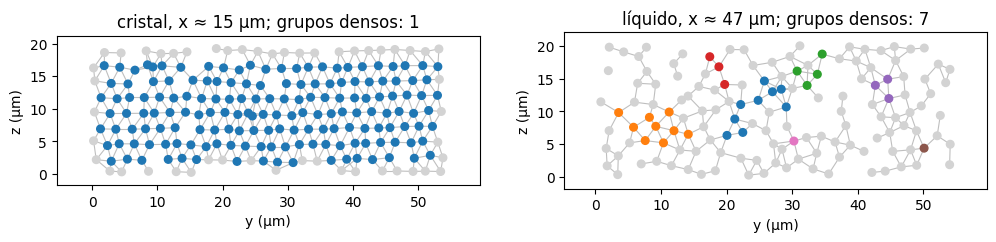

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, j, titulo in [(ax[0], 6, "cristal"), (ax[1], 20, "líquido")]:
    nodos = np.where(capa == j)[0]
    grupos = sorted(nx.connected_components(G.subgraph([u for u in nodos if grado[u] >= 10])), key=len, reverse=True)
    etiqueta = {u: g for g, grupo in enumerate(grupos) for u in grupo}
    colores = [plt.cm.tab10(etiqueta[u] % 10) if u in etiqueta else "lightgray" for u in nodos]
    dibujar(G, X, nodos, colores=colores, ejes=(1, 2), ax=a, node_size=30)
    a.set_title(f"{titulo}, x ≈ {centros[j]:.0f} µm; grupos densos: {len(grupos)}")
plt.show()

### La tabla de grafos
La celda siguiente recorre los 150 instantes y todas las capas, salvo la primera y la última, afectadas por el borde de la imagen. Para cada grafo guarda el instante, la posición de la capa, los cinco rasgos y la fracción de partículas con $N_o>7$, que **no** se usa para entrenar. Tarda menos de un minuto.

In [ ]:
filas = []
for k in range(150):
    Xk, N_ok, _, _ = instante(k)
    Gk = grafo_de_vecinos(Xk, rc)
    grado_k = np.array([Gk.degree(u) for u in range(len(Xk))])
    agrup_k = nx.clustering(Gk)
    agrup_k = np.array([agrup_k[u] for u in range(len(Xk))])
    capa_k = np.digitize(Xk[:, 0], bordes) - 1
    for j in range(1, len(centros) - 1):
        nodos = np.where(capa_k == j)[0]
        # Convertimos el arreglo de NumPy a una lista usando .tolist()
        rasgos_lista = rasgos_de_capa(Gk, grado_k, agrup_k, nodos).tolist()
        filas.append([k, centros[j]] + rasgos_lista + [np.mean(N_ok[nodos] > 7)])

tabla = np.array(filas)
instante_g, xc, R, f_orden = tabla[:, 0], tabla[:, 1], tabla[:, 2:7], tabla[:, 7]
print(len(tabla), "grafos con", R.shape[1], "rasgos")

3450 grafos con 5 rasgos


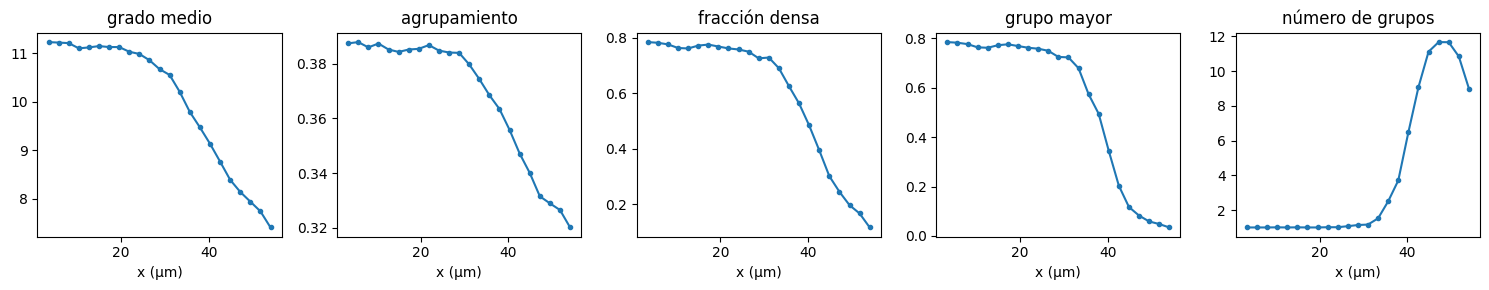

In [ ]:
fig, ax = plt.subplots(1, 5, figsize=(15, 3))
for j in range(5):
    ax[j].plot(np.unique(xc), [R[xc == v, j].mean() for v in np.unique(xc)], "o-", ms=3)
    ax[j].set_title(nombres_capa[j]); ax[j].set_xlabel("x (µm)")
plt.tight_layout()
plt.show()

### Entrenar con los extremos, predecir el medio
Como en el modelo de Ising, entrenamos solo con los grafos de los que estamos seguros: las capas con $x<25$ µm son **cristal** (1) y las capas con $x>42$ µm son **líquido** (0). El modelo decide sobre las capas intermedias, y la interfaz es donde $P(\text{cristal})$ promediada en el tiempo cruza 0,5. La comparamos con la interfaz según el orden orientacional de los autores.

In [ ]:
def cruce(x, f, nivel=0.5):
    """Primera posición donde f, que decrece con x, cruza el nivel (interpolación lineal)."""
    i = np.where(f < nivel)[0][0]
    return x[i - 1] + (nivel - f[i - 1]) * (x[i] - x[i - 1]) / (f[i] - f[i - 1])

entrena = (xc < 25) | (xc > 42)
modelo_capas = entrenar(R[entrena], (xc[entrena] < 30).astype(int))
p_cristal = modelo_capas.predict_proba(R)[:, 1]

xs = np.unique(xc)
P_media = np.array([p_cristal[xc == v].mean() for v in xs])
orden_media = np.array([f_orden[xc == v].mean() for v in xs])
x_grafo, x_orden = cruce(xs, P_media), cruce(xs, orden_media)
print(f"Exactitud en entrenamiento: {modelo_capas.score(R[entrena], (xc[entrena] < 30).astype(int)):.3f}")
print(f"Interfaz según el grafo:               x = {x_grafo:.1f} µm")
print(f"Interfaz según el orden orientacional: x = {x_orden:.1f} µm   (diferencia: {(x_grafo - x_orden) / d:.1f} d)")

Exactitud en entrenamiento: 1.000
Interfaz según el grafo:               x = 37.9 µm
Interfaz según el orden orientacional: x = 31.1 µm   (diferencia: 2.9 d)


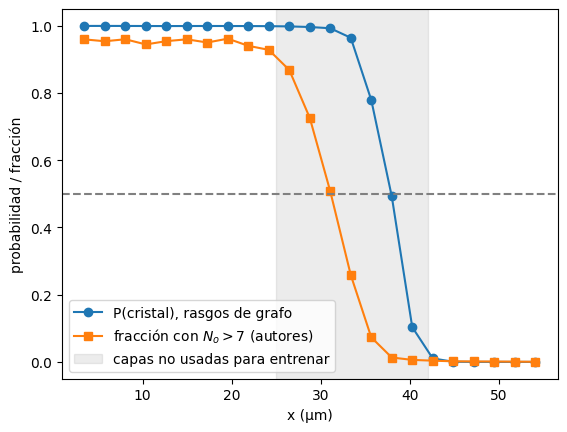

In [ ]:
plt.plot(xs, P_media, "o-", label="P(cristal), rasgos de grafo")
plt.plot(xs, orden_media, "s-", label="fracción con $N_o>7$ (autores)")
plt.axvspan(25, 42, color="gray", alpha=0.15, label="capas no usadas para entrenar")
plt.axhline(0.5, ls="--", color="gray")
plt.xlabel("x (µm)"); plt.ylabel("probabilidad / fracción"); plt.legend()
plt.show()

**Discutan:** las dos curvas cruzan 0,5 en lugares distintos. ¿Cuál describe mejor dónde termina el cristal? ¿Qué detecta el grafo cerca de la interfaz, orden o densidad? Pruebe a mover la ventana de entrenamiento del líquido ($x>36$ o $x>45$ µm): ¿qué pasa con la interfaz del grafo? Los autores encontraron algo parecido con sus propias medidas: el perfil de **densidad** a través de la interfaz es más ancho que el perfil de **orden** ($9{,}6\,d$ frente a $6{,}1\,d$ entre el 10 % y el 90 % del cambio). ¿Es coherente con lo que observa?

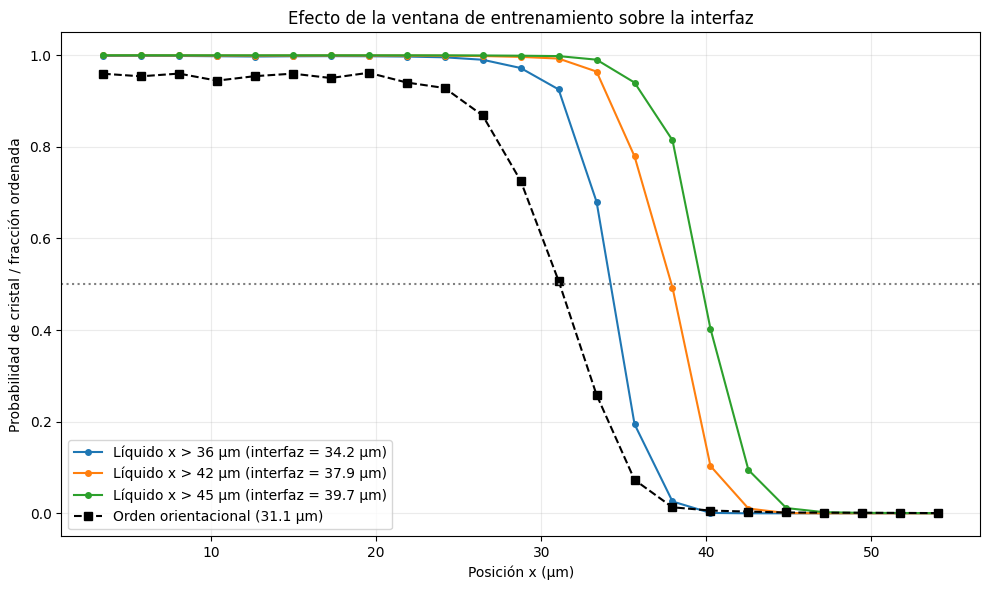


COMPARACIÓN DE ENTRENAMIENTOS
-----------------------------------------------------------------
Límite líquido     Exactitud       Interfaz (µm)  
-----------------------------------------------------------------
x > 36            1.000           34.20          
x > 42            1.000           37.89          
x > 45            1.000           39.71          
-----------------------------------------------------------------
Interfaz por orden orientacional: 31.12 µm


In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Límites que queremos comparar
limites_liquido = [36, 42, 45]

xs = np.unique(xc)

# Orden orientacional de referencia
orden_media = np.array([
    f_orden[xc == v].mean() for v in xs
])
x_orden = cruce(xs, orden_media)

resultados = {}

plt.figure(figsize=(10, 6))

for limite in limites_liquido:

    # 1. Seleccionar regiones para entrenar
    entrena_nuevo = (xc < 25) | (xc > limite)

    # 2. Etiquetas: cristal = 1, líquido = 0
    y_entrena = (xc[entrena_nuevo] < 25).astype(int)

    # 3. Entrenar modelo
    modelo_nuevo = entrenar(
        R[entrena_nuevo],
        y_entrena
    )

    # 4. Probabilidad de cristal en todos los grafos
    p_nueva = modelo_nuevo.predict_proba(R)[:, 1]

    # 5. Promedio temporal por capa
    P_media_nueva = np.array([
        p_nueva[xc == v].mean() for v in xs
    ])

    # 6. Calcular posición de la interfaz
    x_interfaz = cruce(xs, P_media_nueva)

    # 7. Exactitud de entrenamiento
    exactitud = modelo_nuevo.score(
        R[entrena_nuevo],
        y_entrena
    )

    resultados[limite] = {
        "interfaz": x_interfaz,
        "exactitud": exactitud
    }

    # 8. Dibujar curva
    plt.plot(
        xs, P_media_nueva,
        "o-", markersize=4,
        label=f"Líquido x > {limite} µm "
              f"(interfaz = {x_interfaz:.1f} µm)"
    )

# Curva de referencia de los autores
plt.plot(
    xs, orden_media,
    "s--", color="black",
    label=f"Orden orientacional ({x_orden:.1f} µm)"
)

plt.axhline(0.5, color="gray", linestyle=":")

plt.xlabel("Posición x (µm)")
plt.ylabel("Probabilidad de cristal / fracción ordenada")
plt.title("Efecto de la ventana de entrenamiento sobre la interfaz")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# 9. Tabla de resultados
print("\nCOMPARACIÓN DE ENTRENAMIENTOS")
print("-" * 65)
print(f"{'Límite líquido':<18} {'Exactitud':<15} {'Interfaz (µm)':<15}")
print("-" * 65)

for limite, datos in resultados.items():
    print(
        f"x > {limite:<13} "
        f"{datos['exactitud']:<15.3f} "
        f"{datos['interfaz']:<15.2f}"
    )

print("-" * 65)
print(f"Interfaz por orden orientacional: {x_orden:.2f} µm")






# Parte C — Clasificación de grafos: ¿dónde termina el cristal?

## 1. Objetivo

El objetivo de esta parte del laboratorio fue estudiar la transición entre las regiones cristalina y líquida de una muestra de partículas coloidales mediante herramientas de teoría de grafos y aprendizaje automático.

A diferencia de las partes anteriores, donde analizamos partículas individuales y conexiones entre parejas, aquí clasificamos grafos completos correspondientes a capas espaciales de la muestra.

Se analizaron **3450 grafos**, obtenidos a partir de 150 instantes experimentales y 23 capas interiores.

Cada grafo se caracterizó mediante cinco rasgos:

1. Grado medio.
2. Agrupamiento medio.
3. Fracción de partículas densas (grado mayor o igual a 10).
4. Tamaño relativo del mayor grupo conectado de partículas densas.
5. Número de grupos conectados de partículas densas.

Estos rasgos permiten describir la organización colectiva de las partículas y estudiar cómo cambia desde el cristal hasta el líquido.

---

## 2. ¿Qué diferencias encontramos entre los grafos del cristal y del líquido?

La visualización de las capas mostró diferencias estructurales importantes.

En la región cristalina, las partículas presentan una organización espacial regular y las partículas densas forman un único grupo conectado dominante.

En la región líquida, las partículas están distribuidas de manera más irregular y las regiones densas aparecen fragmentadas.

En las capas visualizadas encontramos:

- **Cristal:** 1 grupo conectado de partículas densas.
- **Líquido:** 7 grupos conectados de partículas densas.

Esto indica que la estructura cristalina presenta una conectividad colectiva más organizada, mientras que el líquido presenta grupos densos más pequeños y separados.

---

## 3. ¿Cómo cambian los cinco rasgos a lo largo de la muestra?

Al representar los promedios temporales de los cinco rasgos en función de la posición $x$, encontramos:

| Rasgo | Comportamiento hacia el líquido |
|---|---|
| Grado medio | Disminuye aproximadamente de 11.2 a 7.4 |
| Agrupamiento medio | Disminuye aproximadamente de 0.39 a 0.32 |
| Fracción densa | Disminuye aproximadamente de 0.78 a 0.12 |
| Grupo mayor | Disminuye de aproximadamente 0.78 a valores cercanos a cero |
| Número de grupos | Aumenta hasta aproximadamente 12 y después disminuye |

Estos resultados muestran que las partículas pierden progresivamente conectividad local y que los grandes grupos densos se fragmentan.

El número de grupos aumenta inicialmente porque el grupo dominante se divide en componentes más pequeñas. Posteriormente disminuye porque quedan pocas partículas que cumplen el criterio de alta conectividad.

Los cambios más importantes se observan aproximadamente entre $30$ y $45\,\mu m$, región asociada a la transición estructural.

---

## 4. ¿Cuál de las dos curvas describe mejor dónde termina el cristal?

Se compararon dos criterios para localizar la interfaz:

- La probabilidad de cristal obtenida mediante los cinco rasgos del grafo.
- La fracción de partículas con orden orientacional $N_o>7$.

Utilizando el cruce con el valor 0.5, se obtuvieron:

$$
x_{\mathrm{grafo}}=37.9\,\mu m
$$

$$
x_{\mathrm{orden}}=31.1\,\mu m
$$

La diferencia fue:

$$
\Delta x=37.9-31.1=6.8\,\mu m
$$

Considerando el diámetro de las partículas, $d=2.30\,\mu m$:

$$
\frac{\Delta x}{d}\approx2.9
$$

**Respuesta:**

Si queremos identificar específicamente dónde desaparece el orden cristalino, el criterio orientacional resulta más apropiado porque mide directamente la organización local de las partículas.

El clasificador de grafos identifica, en cambio, dónde la conectividad y la estructura colectiva dejan de parecerse a las del cristal.

Por tanto, ambas curvas describen propiedades físicas diferentes y no tienen por qué cruzar 0.5 en la misma posición.

---

## 5. ¿Qué detecta el grafo cerca de la interfaz: orden o densidad?

Los resultados sugieren que nuestro clasificador detecta principalmente características relacionadas con la **conectividad, la coordinación local y la organización de regiones densas**.

Esto se debe a que los cinco rasgos utilizados dependen del número de vecinos, de sus conexiones y de los grupos que forman las partículas con alta conectividad.

En consecuencia, una capa puede haber perdido gran parte de su orden orientacional y todavía conservar una estructura de conexiones semejante a la del cristal.

Esto explica por qué la interfaz calculada mediante grafos aparece más hacia el lado líquido que la interfaz orientacional.

Sin embargo, es importante aclarar que los rasgos del grafo no constituyen una medida directa de la densidad física ni de la fracción de volumen.

**Conclusión:** nuestro modelo parece ser más sensible a la conectividad estructural que al orden orientacional.

---

## 6. ¿Qué sucede al cambiar la ventana de entrenamiento del líquido?

Para estudiar la estabilidad del resultado, mantuvimos la región cristalina de entrenamiento en $x<25\,\mu m$ y modificamos el límite utilizado para seleccionar los grafos líquidos.

Los resultados fueron:

| Región líquida de entrenamiento | Interfaz del grafo | Diferencia con el orden orientacional |
|---|---:|---:|
| $x>36\,\mu m$ | 34.2 µm | 3.1 µm |
| $x>42\,\mu m$ | 37.9 µm | 6.8 µm |
| $x>45\,\mu m$ | 39.7 µm | 8.6 µm |

La interfaz orientacional permaneció en:

$$
x_{\mathrm{orden}}=31.1\,\mu m
$$

**Respuesta:**

Al seleccionar regiones líquidas cada vez más alejadas de la interfaz, la posición estimada por el clasificador se desplaza hacia valores mayores de $x$.

La interfaz calculada mediante grafos cambió de $34.2$ a $39.7\,\mu m$.

Esto demuestra que la predicción depende de las regiones utilizadas para entrenar.

Por tanto, la posición $37.9\,\mu m$ no debe interpretarse como una frontera física única e independiente de la selección de entrenamiento.

Sin embargo, en los tres casos la interfaz del grafo permanece a la derecha de la interfaz orientacional.

---

## 7. ¿Es coherente lo observado con los resultados de los autores?

Los autores encontraron que el perfil de densidad presenta una transición espacial más ancha que el perfil de orden orientacional.

Sus resultados fueron:

$$
w_{\mathrm{densidad}}=9.6d
$$

$$
w_{\mathrm{orden}}=6.1d
$$

Estas anchuras corresponden al intervalo espacial entre el 10 % y el 90 % del cambio de cada propiedad.

Nuestros resultados son cualitativamente coherentes con esta observación.

Encontramos que el orden orientacional disminuye antes de que desaparezcan las características de conectividad que el clasificador asocia con el cristal.

Esto sugiere que la pérdida de orden y la reorganización de la conectividad no ocurren necesariamente en la misma posición.

No obstante, debemos distinguir dos cantidades:

- Los autores comparan **anchuras de transición**.
- Nosotros comparamos principalmente **posiciones de cruce al 50 %**.

Por tanto, nuestros resultados apoyan una interpretación física compatible con la de los autores, pero no reproducen directamente sus valores de anchura.

---

## 8. ¿Qué significa que la exactitud de entrenamiento sea 1.000?

El modelo obtuvo una exactitud de entrenamiento de:

$$
\mathrm{Accuracy}=1.000
$$

Esto significa que clasificó correctamente el 100 % de los grafos utilizados durante el entrenamiento.

Sin embargo, el entrenamiento se realizó únicamente con capas claramente cristalinas y líquidas.

Por tanto, esta exactitud no garantiza que el modelo clasifique correctamente todas las capas intermedias.

La interfaz es precisamente la región donde aparecen características estructurales mixtas y donde la clasificación resulta más difícil.

Para evaluar rigurosamente la capacidad de generalización sería necesario utilizar datos independientes de entrenamiento.

---

# Conclusiones generales de la Parte C

**1. La teoría de grafos permite caracterizar la estructura colectiva de las partículas.**

Los cinco rasgos utilizados describen la conectividad local y la organización de grupos densos, permitiendo estudiar diferencias entre regiones cristalinas y líquidas.

**2. El cristal presenta una estructura más organizada y conectada.**

En la región cristalina predominan grupos densos extensos, mientras que en el líquido las partículas densas forman componentes más pequeñas y fragmentadas.

**3. La transición cristal-líquido se manifiesta mediante cambios importantes en los rasgos del grafo.**

Al avanzar hacia el líquido disminuyen el grado medio, el agrupamiento, la fracción densa y el tamaño del grupo mayor. El número de grupos aumenta durante la fragmentación y posteriormente disminuye.

**4. El orden orientacional y la conectividad estructural no identifican exactamente la misma interfaz.**

El orden orientacional sitúa la interfaz en $31.1\,\mu m$, mientras que el clasificador original de grafos la sitúa en $37.9\,\mu m$.

Esto sugiere que las características de conectividad asociadas al cristal pueden persistir después de que se haya perdido gran parte del orden orientacional.

**5. La posición estimada mediante grafos depende de la ventana de entrenamiento.**

Al cambiar el límite del líquido entre $36$ y $45\,\mu m$, la interfaz predicha varió entre $34.2$ y $39.7\,\mu m$.

Esto demuestra la importancia de evaluar la sensibilidad del clasificador antes de interpretar físicamente sus predicciones.

**6. Los resultados son compatibles con las observaciones experimentales de los autores.**

Los autores encontraron una transición de densidad más ancha que la de orden orientacional, lo cual es coherente con que la pérdida de organización cristalina y los cambios de conectividad ocurran en escalas espaciales diferentes.

## Conclusión final

La Parte C demuestra que es posible utilizar la teoría de grafos y el aprendizaje automático para estudiar la transición entre cristal y líquido en un sistema experimental de partículas coloidales.

El resultado más importante es que **la pérdida del orden cristalino no coincide necesariamente con la pérdida de las características de conectividad propias del cristal**.

Mientras el orden orientacional identifica la transición alrededor de $31.1\,\mu m$, el clasificador de grafos encuentra una transición estructural más desplazada hacia el líquido, cuya posición depende de las regiones seleccionadas para entrenar.

Por tanto, los grafos proporcionan una descripción complementaria del sistema, útil para estudiar cómo cambia la organización colectiva de las partículas durante la transición de fase.


# Para la exposición (un equipo aleatoriamente presentará una parte)

Todos los equipos resuelven las tres partes. Para la exposición, prepare una tabla o figura de cada parte (A,B,C), presente las respuestas de la discusión y adicional responda:

- **Parte A.** ¿Cuánto mejora la agregación y por qué? ¿Dónde se equivoca el modelo?
- **Parte B.** ¿En qué zona cambian más los vecinos? ¿Por qué la distancia predice mejor que los vecinos comunes?
- **Parte C.** ¿Por qué la interfaz del grafo no coincide con la del orden orientacional, y cómo depende de la ventana de entrenamiento?

¿qué información de la muestra no captura el grafo de vecinos, y qué habría que añadirle para distinguir un cristal de un líquido denso?

# Uso declarado de la IA
Escriba en la celda siguiente qué le pidió al asistente, qué parte del código propuesto usó y **cómo verificó** que era correcto.


# Preparación para la exposición — Partes A, B y C

## Parte A. Clasificación de nodos

### ¿Cuánto mejora la agregación y por qué?

En esta parte buscamos clasificar cada partícula como cristalina o líquida a partir de las características de su entorno en el grafo.

Los resultados fueron:

| Características utilizadas | Exactitud general | Exactitud en la interfaz |
|---|---:|---:|
| Clase mayoritaria | 0.562 | 0.531 |
| Solo grado | 0.772 | 0.577 |
| Grado y agrupamiento | 0.811 | 0.608 |
| Cinco rasgos | 0.891 | 0.684 |

Al pasar de utilizar únicamente el grado a utilizar los cinco rasgos, la exactitud general aumentó de 77.2 % a 89.1 %.

$$
\Delta A=89.1\%-77.2\%=11.9
$$

Esto representa una mejora de **11.9 puntos porcentuales**.

En la interfaz, la exactitud aumentó de 57.7 % a 68.4 %, una mejora de **10.7 puntos porcentuales**.

La mejora ocurre porque el grado solamente indica cuántos vecinos tiene una partícula, mientras que los demás rasgos incorporan información sobre cómo están conectados esos vecinos y cómo se organiza su entorno.

En particular, la agregación de información de uno y dos saltos permite considerar la estructura más allá de la partícula individual.

Es importante señalar que la mejora corresponde al conjunto completo de características, que también incluye medidas de agrupamiento, y no exclusivamente a la agregación.

### ¿Dónde se equivoca el modelo?

El modelo presenta mayores dificultades en la región de interfaz entre el cristal y el líquido.

En esta región coexisten partículas con características estructurales intermedias, lo que dificulta distinguirlas utilizando únicamente la conectividad.

La exactitud disminuye de 89.1 % en el conjunto general a 68.4 % en la interfaz.

Esto indica que las características del grafo son útiles para identificar las regiones claramente cristalinas y líquidas, pero resultan menos discriminativas cerca de la transición.

**Conclusión de la Parte A:** incorporar información del entorno de las partículas mejora considerablemente la clasificación, aunque la interfaz sigue siendo la región más difícil.

---

## Parte B. Predicción de conexiones nuevas y enlaces rotos

### ¿En qué zona cambian más los vecinos?

Los resultados de formación de enlaces nuevos fueron:

| Región | Fracción de conexiones nuevas | AUC vecinos comunes | AUC distancia |
|---|---:|---:|---:|
| Cristal | 0.8 % | 0.898 | 0.963 |
| Interfaz | 4.0 % | 0.752 | 0.873 |
| Líquido | 10.5 % | 0.643 | 0.784 |

Los resultados de ruptura de enlaces fueron:

| Región | Fracción de enlaces rotos | AUC -vecinos comunes | AUC longitud |
|---|---:|---:|---:|
| Cristal | 2.1 % | 0.525 | 0.916 |
| Interfaz | 13.6 % | 0.579 | 0.712 |
| Líquido | 40.7 % | 0.523 | 0.591 |

La región líquida presenta la mayor proporción de conexiones nuevas y de conexiones rotas dentro de los conjuntos analizados.

Esto ocurre porque las partículas del líquido tienen mayor libertad de movimiento y reorganizan continuamente sus relaciones de vecindad.

En el cristal, las partículas mantienen posiciones relativamente estables y conservan gran parte de sus conexiones iniciales.

Las fracciones de formación y ruptura utilizan conjuntos de parejas diferentes, por lo que no deben sumarse directamente.

### ¿Por qué la distancia predice mejor que los vecinos comunes?

La distancia inicial conserva información geométrica que no está completamente representada en el grafo.

En nuestro modelo, dos partículas están conectadas cuando su separación es menor o igual al radio de vecindad:

$$
r_c=3.243\,\mu m
$$

Sin embargo, el grafo solamente registra si existe o no una conexión.

Por ejemplo, dos parejas separadas por 3.3 y 5.0 micrómetros aparecen igualmente desconectadas, aunque la primera se encuentra mucho más cerca del umbral de vecindad.

La distancia permite distinguir esas situaciones.

Esto explica que la distancia inicial obtenga mejores valores de AUC que los vecinos comunes en las tres regiones.

En el cristal, por ejemplo:

$$
AUC_{\mathrm{distancia}}=0.963
$$

$$
AUC_{\mathrm{vecinos}}=0.898
$$

En la predicción de rupturas ocurre algo similar: los enlaces inicialmente más largos pueden estar más cerca de superar el radio de vecindad.

**Conclusión de la Parte B:** las conexiones cambian proporcionalmente más en el líquido, pero esos cambios son más difíciles de predecir. La distancia resulta especialmente útil porque conserva información geométrica que se pierde al representar las partículas mediante conexiones binarias.

---

## Parte C. Clasificación de grafos e interfaz cristal-líquido

### ¿Por qué la interfaz del grafo no coincide con la del orden orientacional?

En esta parte clasificamos grafos completos correspondientes a capas de la muestra.

Utilizamos cinco características: grado medio, agrupamiento medio, fracción densa, tamaño del grupo mayor y número de grupos conectados.

Los resultados originales fueron:

| Método | Posición de la interfaz |
|---|---:|
| Orden orientacional | 31.1 µm |
| Clasificador de grafos | 37.9 µm |

La diferencia fue de 6.8 micrómetros, equivalente a aproximadamente 2.9 diámetros de partícula.

Esto ocurre porque ambos métodos estudian propiedades diferentes.

El orden orientacional mide la organización local característica de la estructura cristalina.

En cambio, los rasgos del grafo describen principalmente la conectividad, la coordinación local y la organización de grupos densos.

Por tanto, una región puede perder su orden cristalino y todavía conservar una conectividad semejante a la del cristal.

Esto explica que la interfaz del grafo aparezca desplazada hacia el líquido.

### ¿Cómo depende la interfaz de la ventana de entrenamiento?

Mantuvimos la región cristalina de entrenamiento en $x<25\,\mu m$ y modificamos el límite utilizado para seleccionar las capas líquidas.

Los resultados fueron:

| Región líquida utilizada | Interfaz estimada |
|---|---:|
| $x>36\,\mu m$ | 34.2 µm |
| $x>42\,\mu m$ | 37.9 µm |
| $x>45\,\mu m$ | 39.7 µm |

Al seleccionar capas líquidas más alejadas de la transición, la interfaz estimada se desplaza hacia valores mayores de $x$.

Esto demuestra que el clasificador es sensible a las regiones utilizadas durante el entrenamiento.

Sin embargo, en los tres casos la interfaz del grafo permanece más hacia el lado líquido que la interfaz orientacional.

Los resultados son cualitativamente coherentes con los autores, quienes encontraron que el perfil de densidad presenta una transición más ancha que el perfil de orden orientacional:

$$
w_{\mathrm{densidad}}=9.6d
$$

$$
w_{\mathrm{orden}}=6.1d
$$

Estas anchuras no deben confundirse con las posiciones de cruce al 50 % que calculamos en nuestro laboratorio.

**Conclusión de la Parte C:** la conectividad estructural puede conservar características semejantes a las del cristal incluso después de que se haya perdido gran parte del orden orientacional. Además, la posición de la interfaz estimada mediante grafos depende de la selección de los datos de entrenamiento.

---

# Pregunta general

## ¿Qué información de la muestra no captura el grafo de vecinos y qué habría que añadir para distinguir un cristal de un líquido denso?

El grafo de vecinos representa las partículas como nodos y sus relaciones de proximidad como aristas.

Sin embargo, esta representación no conserva toda la información física del sistema.

En particular, un grafo binario de vecindad no describe directamente:

1. **Las distancias exactas entre partículas:** solamente registra si están dentro del radio de vecindad.
2. **Los ángulos entre vecinos:** fundamentales para reconocer la organización geométrica característica de un cristal.
3. **El orden orientacional:** permite distinguir una estructura cristalina ordenada de otra con conectividad similar pero desordenada.
4. **El movimiento de las partículas:** un grafo de un solo instante no describe velocidades, desplazamientos ni persistencia temporal de las conexiones.
5. **La fracción de volumen local:** la conectividad puede relacionarse con la densidad, pero no la mide directamente.

Para mejorar la clasificación de un cristal frente a un líquido denso, podríamos incorporar:

- Distancias entre partículas como pesos de las aristas.
- Ángulos y parámetros de orden orientacional.
- Fracción de volumen o densidad local.
- Información temporal sobre desplazamientos y cambios de vecinos.

**Respuesta principal:**

Un líquido denso puede tener aproximadamente tantos vecinos como un cristal, pero carecer de su organización geométrica regular y persistente.

Por eso, contar conexiones no siempre es suficiente para distinguir ambas fases.

Necesitamos complementar la topología del grafo con información geométrica, orientacional y dinámica.

---

# Conclusiones generales del laboratorio

**1. Parte A — Clasificación de partículas**

La información del entorno mejora la clasificación de partículas cristalinas y líquidas. Al utilizar cinco rasgos, la exactitud general aumenta hasta 89.1 %, aunque disminuye en la interfaz.

**2. Parte B — Evolución de conexiones**

El líquido presenta la mayor proporción de formación y ruptura de conexiones. La distancia inicial supera a los vecinos comunes como predictor, porque conserva información geométrica que el grafo binario no representa.

**3. Parte C — Clasificación de capas**

Los grafos permiten identificar cambios colectivos de conectividad entre cristal y líquido. Sin embargo, la interfaz estimada mediante grafos no coincide exactamente con la obtenida mediante orden orientacional y depende de la ventana de entrenamiento.

**4. Interpretación física general**

La conectividad, el orden orientacional y la dinámica describen aspectos diferentes de la estructura de la materia.

Una región puede conservar muchos vecinos sin presentar una organización cristalina.

Por ello, la teoría de grafos es una herramienta útil para estudiar sistemas de partículas, pero debe complementarse con información geométrica y física para caracterizar completamente sus fases.

---

# Uso declarado de la inteligencia artificial

## ¿Qué se le pidió al asistente?

Se utilizó ChatGPT como herramienta de apoyo para comprender conceptos de teoría de grafos, interpretar resultados experimentales y revisar código Python.

Las consultas estuvieron relacionadas con:

- La clasificación de nodos mediante características estructurales.
- La interpretación del AUC en la predicción de enlaces.
- El cálculo y la visualización de conexiones nuevas y rotas.
- La implementación de los cinco rasgos de una capa.
- La comparación de diferentes ventanas de entrenamiento para localizar la interfaz cristal-líquido.
- La interpretación física de las gráficas y la organización de las conclusiones.

## ¿Qué parte del código propuesto se utilizó?

Se utilizó código sugerido por el asistente para completar la función `rasgos_de_capa`, calcular las características de las capas y analizar componentes conectadas.

También se utilizó código para visualizar conexiones rotas y comparar las posiciones de interfaz obtenidas con diferentes ventanas de entrenamiento.

Se realizaron ajustes en las celdas de Python cuando aparecieron errores, como la conversión de arreglos NumPy a listas mediante `.tolist()` y la definición de variables necesarias para ejecutar los cálculos.

## ¿Cómo se verificó que el código era correcto?

La verificación se realizó mediante las pruebas del laboratorio y la inspección de los resultados.

En la Parte C, la función `rasgos_de_capa` superó las comprobaciones con `assert`, incluyendo la igualdad entre el número de componentes conectadas y la multiplicidad del autovalor cero del Laplaciano.

También se comprobó que la tabla contenía 3450 grafos con cinco características.

En la Parte B, se revisaron las fracciones de enlaces nuevos y rotos, los valores de AUC y las visualizaciones de conexiones.

Finalmente, en la Parte C, se compararon las curvas de probabilidad de cristal obtenidas con tres ventanas de entrenamiento y se verificó que el caso original $x>42\,\mu m$ reprodujera la interfaz de $37.9\,\mu m$.

La interpretación física se contrastó con los resultados experimentales y las preguntas propuestas en el laboratorio.

## Declaración final

La inteligencia artificial se utilizó como herramienta de apoyo para la programación, la explicación de conceptos y la interpretación de resultados. Los cálculos se ejecutaron sobre los datos experimentales del laboratorio y se revisaron mediante pruebas de código, resultados numéricos y gráficas.

La responsabilidad de comprender, verificar y presentar los resultados corresponde al estudiante.


*Escriba aquí su declaración.*

## Uso declarado de la inteligencia artificial

Durante el desarrollo del laboratorio utilicé ChatGPT como herramienta de apoyo para comprender los conceptos de teoría de grafos, interpretar los resultados y completar algunas partes del código en Python.

**¿Qué le pedí al asistente?**

Le solicité explicaciones sobre la clasificación de nodos, la predicción de enlaces, el significado del AUC y la clasificación de grafos. También le pedí ayuda para completar la función `rasgos_de_capa`, visualizar las conexiones que se rompen y comparar diferentes ventanas de entrenamiento en la Parte C.

**¿Qué código propuesto utilicé?**

Utilicé y adapté el código sugerido para calcular los cinco rasgos de las capas, visualizar enlaces rotos y repetir el entrenamiento del clasificador con diferentes límites para la región líquida ($x>36$, $x>42$ y $x>45\,\mu m$). El resto del procedimiento se desarrolló siguiendo las instrucciones y funciones proporcionadas en el laboratorio.

**¿Cómo verifiqué que era correcto?**

Ejecuté el código en Jupyter Notebook y revisé los resultados numéricos y las gráficas. En la Parte C, comprobé que la función `rasgos_de_capa` superara las pruebas `assert`, incluyendo la verificación del número de componentes conectadas mediante los autovalores del Laplaciano. También confirmé la construcción de 3450 grafos con cinco rasgos y que el entrenamiento original reprodujera una interfaz de $37.9\,\mu m$.

Cuando aparecieron errores de programación, revisé las variables y corregí el código antes de continuar.

**En conclusión**, la inteligencia artificial fue utilizada como apoyo para comprender, programar e interpretar el laboratorio. Los resultados se obtuvieron ejecutando el código sobre los datos experimentales y verificando su funcionamiento mediante las pruebas y visualizaciones realizadas.


**Datos:** J. Hernández-Guzmán y E. R. Weeks, «The equilibrium intrinsic crystal–liquid interface of colloids», *Proc. Natl. Acad. Sci. USA* **106**(36), 15198–15202 (2009), [doi:10.1073/pnas.0904682106](https://doi.org/10.1073/pnas.0904682106). Datos publicados por el grupo de E. R. Weeks (Emory University).